In [3]:
import os
import sys
import subprocess
import importlib.util
from typing import Dict, List, Set, Tuple, Optional

def garantir_pacote(pacote: str) -> None:
    """Verifica se o pacote está instalado e instala via pip caso não esteja."""
    if importlib.util.find_spec(pacote) is None:
        print(f"Instalando biblioteca necessária: {pacote}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pacote])

for lib in ["networkx", "matplotlib"]:
    garantir_pacote(lib)

import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Resolução portável de diretórios a partir da raiz do repositório
DIRETORIO_RAIZ = os.path.abspath(".")
PASTA_TESTES = os.path.join(DIRETORIO_RAIZ, "tests")
PASTA_FIGURAS = os.path.join(DIRETORIO_RAIZ, "output", "figures")

os.makedirs(PASTA_TESTES, exist_ok=True)
os.makedirs(PASTA_FIGURAS, exist_ok=True)

print("[OK] Dependências verificadas (networkx, matplotlib).")
print("[OK] Diretório de entradas (.txt):", os.path.relpath(PASTA_TESTES))
print("[OK] Diretório de exportação de imagens (.png):", os.path.relpath(PASTA_FIGURAS))
print("[OK] Arquivos de teste encontrados em tests/:", sorted(os.listdir(PASTA_TESTES)))

[OK] Dependências verificadas (networkx, matplotlib).
[OK] Diretório de entradas (.txt): tests
[OK] Diretório de exportação de imagens (.png): output/figures
[OK] Arquivos de teste encontrados em tests/: ['caso_extra_multiplos_ciclos.txt', 'caso_grafo1_concorrente_seguro.txt', 'caso_grafo2_espera_circular.txt', 'caso_slide40_multiplos_nos.txt']


In [4]:
def carregar_e_validar_grafo(
    caminho_arquivo: str
) -> Tuple[List[str], List[str], Dict[str, List[str]], List[Tuple[str, str]]]:
    """
    Lê um arquivo .txt no formato Opção 1 (Lista de Arestas) e valida:
      1. Disjunção entre conjuntos de Processos e Recursos.
      2. Propriedade de Grafo Dirigido Bipartido (Processo <-> Recurso).
      3. Restrição de instância única por recurso (no máximo 1 arco R -> P por recurso).
    """
    processos: List[str] = []
    recursos: List[str] = []
    arestas: List[Tuple[str, str]] = []
    lendo_arestas = False

    with open(caminho_arquivo, "r", encoding="utf-8") as f:
        for num_linha, linha_bruta in enumerate(f, 1):
            linha = linha_bruta.split("#")[0].strip()
            if not linha:
                continue
            partes = linha.split()
            cabecalho = partes[0].upper()

            if cabecalho == "PROCESSOS":
                processos.extend(partes[1:])
                lendo_arestas = False
            elif cabecalho == "RECURSOS":
                recursos.extend(partes[1:])
                lendo_arestas = False
            elif cabecalho == "ARESTAS":
                lendo_arestas = True
            elif lendo_arestas and len(partes) == 2:
                arestas.append((partes[0], partes[1]))
            else:
                raise ValueError(f"Formato inválido na linha {num_linha}: '{linha}'")

    conj_proc = set(processos)
    conj_rec = set(recursos)
    if conj_proc.intersection(conj_rec):
        raise ValueError("Erro semântico: Há nós declarados como Processo e Recurso simultaneamente.")

    recursos_em_posse: Dict[str, str] = {}
    adjacencia: Dict[str, List[str]] = {no: [] for no in processos + recursos}

    for u, v in arestas:
        if u not in adjacencia or v not in adjacencia:
            raise ValueError(f"Nó não declarado na aresta ({u} -> {v}).")
        if (u in conj_proc and v in conj_proc) or (u in conj_rec and v in conj_rec):
            raise ValueError(f"Violação de grafo bipartido em ({u} -> {v}): arestas devem alternar Processo e Recurso.")
        if u in conj_rec and v in conj_proc:
            if u in recursos_em_posse and recursos_em_posse[u] != v:
                raise ValueError(f"Violação de instância única: Recurso '{u}' alocado simultaneamente a '{recursos_em_posse[u]}' e '{v}'.")
            recursos_em_posse[u] = v
        adjacencia[u].append(v)

    return processos, recursos, adjacencia, arestas

# Demonstração rápida do parser no Caso T1
_p, _r, _adj, _ar = carregar_e_validar_grafo(os.path.join(PASTA_TESTES, "caso_slide40_multiplos_nos.txt"))
print("[OK] Módulo de leitura e validação bipartida carregado com sucesso!")
print(f"Teste rápido de leitura (T1 - Slide 40): {len(_p)} processos, {len(_r)} recursos e {len(_ar)} arestas validadas.")

[OK] Módulo de leitura e validação bipartida carregado com sucesso!
Teste rápido de leitura (T1 - Slide 40): 7 processos, 6 recursos e 13 arestas validadas.


In [5]:
def isolar_ciclo_elementar(lista_L: List[str], no_repetido: str, ordem_nos: Dict[str, int]) -> List[str]:
    """Remove o caminho prefixo anterior ao nó repetido e ancora o ciclo no primeiro processo/nó declarado."""
    idx_inicio = lista_L.index(no_repetido)
    nucleo = lista_L[idx_inicio:]
    ancora = min(nucleo, key=lambda n: ordem_nos.get(n, 9999))
    idx_ancora = nucleo.index(ancora)
    return nucleo[idx_ancora:] + nucleo[:idx_ancora] + [ancora]


def normalizar_ciclo(ciclo: List[str]) -> Tuple[str, ...]:
    """Gera assinatura canônica rotacionada para evitar registrar o mesmo ciclo duas vezes."""
    nos = ciclo[:-1]
    menor = min(nos)
    idx = nos.index(menor)
    return tuple(nos[idx:] + nos[:idx])


def formatar_resultado(ciclos: List[List[str]]) -> str:
    """Formata a saída oficial conforme especificação do Trabalho 2."""
    if not ciclos:
        return "Sem deadlock"
    if len(ciclos) == 1:
        return f"Há deadlock ({' -> '.join(ciclos[0])})"
    linhas = [f"Há deadlock ({len(ciclos)} ciclos encontrados):"]
    for i, c in enumerate(ciclos, 1):
        linhas.append(f"  Ciclo {i}: {' -> '.join(c)}")
    return "\n".join(linhas)


def detectar_impasses_dfs(
    processos: List[str],
    recursos: List[str],
    adjacencia: Dict[str, List[str]],
    buscar_todos: bool = False
) -> Tuple[List[List[str]], List[str]]:
    """
    Executa a Busca em Profundidade (DFS) seguindo o algoritmo do Slide 40:
      - Mantém a lista ordenada L de nós no caminho atual.
      - Marca os arcos percorridos.
      - Retrocede (backtracking) ao encontrar um beco sem saída.
    """
    ciclos: List[List[str]] = []
    assinaturas: Set[Tuple[str, ...]] = set()
    log_passos: List[str] = []
    todos_nos = processos + recursos
    ordem_nos = {no: i for i, no in enumerate(todos_nos)}

    def percorrer_ramo_dfs_recursivo(
        no_atual: str,
        lista_L: List[str],
        arcos_marcados: Set[Tuple[str, str]]
    ) -> Optional[List[str]]:
        if no_atual in lista_L:
            ciclo_limpo = isolar_ciclo_elementar(lista_L, no_atual, ordem_nos)
            log_passos.append(
                f"  [CICLO DETECTADO!] Nó '{no_atual}' repetido em L={lista_L + [no_atual]} "
                f"-> Ciclo extraído: {' -> '.join(ciclo_limpo)}"
            )
            assinatura = normalizar_ciclo(ciclo_limpo)
            if assinatura not in assinaturas:
                assinaturas.add(assinatura)
                ciclos.append(ciclo_limpo)
            return ciclo_limpo

        lista_L.append(no_atual)
        log_passos.append(f"  [Avanço] Visitando '{no_atual}' | Lista L: {lista_L}")

        for vizinho in adjacencia.get(no_atual, []):
            arco = (no_atual, vizinho)
            if arco not in arcos_marcados:
                arcos_marcados.add(arco)
                log_passos.append(f"    -> Marcando arco ({no_atual} -> {vizinho})")
                achado = percorrer_ramo_dfs_recursivo(vizinho, lista_L, arcos_marcados)
                if achado is not None and not buscar_todos:
                    return achado

        lista_L.pop()
        log_passos.append(f"  [Retrocesso] Beco sem saída em '{no_atual}' | Lista L: {lista_L}")
        return None

    for raiz in todos_nos:
        log_passos.append(f"--- Iniciando busca DFS com raiz em '{raiz}' ---")
        res = percorrer_ramo_dfs_recursivo(raiz, [], set())
        if res is not None and not buscar_todos:
            break

    return ciclos, log_passos

print("[OK] Motor recursivo DFS e extrator de ciclos elementares carregados com sucesso!")

[OK] Motor recursivo DFS e extrator de ciclos elementares carregados com sucesso!


In [6]:
# Paleta de cores padronizada conforme os slides da aula
COR_NO_DEADLOCK = "#e74c3c"       # Vermelho: vértice preso em espera circular
COR_NO_SEGURO = "#2ecc71"         # Verde: vértice inspecionado sem ciclo
COR_PROCESSO_CIRCULO = "#3498db"  # Azul: Processo (Círculo conforme Slide)
COR_RECURSO_QUADRADO = "#7ae2ff"  # Ciano: Recurso (Quadrado conforme Slide)
COR_ARESTA_NORMAL = "#7f8c8d"     # Cinza: arco normal
COR_ARESTA_CICLO = "#c0392b"      # Vermelho escuro: arco pertencente ao ciclo


def salvar_cartao_diagnostico(
    titulo: str,
    processos: List[str],
    recursos: List[str],
    arestas: List[Tuple[str, str]],
    ciclos: List[List[str]],
    nome_png: str
) -> str:
    """Gera cartão visual de telemetria, salva em output/figures/ e retorna o caminho do arquivo."""
    conj_p = set(processos)
    posse = [f"{u}->{v}" for u, v in arestas if u not in conj_p]
    espera = [f"{u}->{v}" for u, v in arestas if u in conj_p]

    fig, ax = plt.subplots(figsize=(12.5, 2.7))
    ax.set_axis_off()
    veredito = formatar_resultado(ciclos).replace("\n", " | ")
    sep = "-" * 106
    txt = (
        f"RELATÓRIO DE DETECÇÃO DE IMPASSE (DFS) - CASO: [ {titulo} ]\n"
        f"{sep}\n"
        f"Processos Círculos ({len(processos)}): {', '.join(processos)}   |   "
        f"Recursos Quadrados ({len(recursos)}): {', '.join(recursos)}\n"
        f"Arcos de Posse (R->P): {', '.join(posse)}   |   "
        f"Arcos de Solicitação (P->R): {', '.join(espera)}\n\n"
        f"Diagnóstico Final (Algoritmo Slide 40):  {veredito}"
    )
    cor_b = "#e74c3c" if ciclos else "#2ecc71"
    cor_f = "#fdf2e9" if ciclos else "#eafaf1"
    plt.text(
        0.015, 0.5, txt, family="monospace", fontsize=9.8,
        verticalalignment="center", linespacing=1.55, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.65", facecolor=cor_f, edgecolor=cor_b, lw=2.2)
    )
    caminho = os.path.join(PASTA_FIGURAS, nome_png)
    plt.savefig(caminho, bbox_inches="tight", dpi=300, facecolor="white")
    plt.close(fig)
    return caminho


def desenhar_comparativo_rag(
    titulo: str,
    processos: List[str],
    recursos: List[str],
    arestas: List[Tuple[str, str]],
    ciclos: List[List[str]],
    nome_png: str
) -> str:
    """Desenha o Grafo de Alocação (Círculos = Processos, Quadrados = Recursos), salva em output/figures/ e retorna o caminho."""
    G = nx.DiGraph()
    for no in processos + recursos:
        G.add_node(no)
    for u, v in arestas:
        G.add_edge(u, v)

    pos: Dict[str, Tuple[float, float]] = {}
    largura = max(len(processos), len(recursos), 1) * 2.5
    for i, p in enumerate(processos):
        passo = largura / max(len(processos), 1)
        pos[p] = ((i - (len(processos) - 1) / 2.0) * passo, 2.8)
    for i, r in enumerate(recursos):
        passo = largura / max(len(recursos), 1)
        pos[r] = ((i - (len(recursos) - 1) / 2.0) * passo, 0.6)

    nos_c: Set[str] = set()
    arestas_c: Set[Tuple[str, str]] = set()
    for c in ciclos:
        nos_c.update(c)
        for i in range(len(c) - 1):
            arestas_c.add((c[i], c[i + 1]))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5, 6.4))

    # Painel Esquerdo: Grafo Original (Círculos Azuis = Processos | Quadrados Cianos = Recursos)
    nx.draw_networkx_nodes(G, pos, nodelist=processos, ax=ax1, node_shape="o", node_size=1450, node_color=COR_PROCESSO_CIRCULO, edgecolors="#1b4f72", linewidths=1.8)
    nx.draw_networkx_nodes(G, pos, nodelist=recursos, ax=ax1, node_shape="s", node_size=1350, node_color=COR_RECURSO_QUADRADO, edgecolors="#117864", linewidths=1.8)
    nx.draw_networkx_labels(G, pos, ax=ax1, font_size=11.5, font_weight="bold", font_color="#17202a")
    nx.draw_networkx_edges(G, pos, ax=ax1, arrows=True, arrowsize=20, edge_color=COR_ARESTA_NORMAL, width=2.0, node_size=1450, connectionstyle="arc3,rad=0.07")
    ax1.set_title(f"Grafo de Alocação de Recursos ({titulo})\n● Círculos: Processos ({len(processos)})   |   ■ Quadrados: Recursos ({len(recursos)})", fontsize=11.5, fontweight="bold", pad=12)
    ax1.margins(0.18)
    ax1.set_axis_off()

    # Painel Direito: Diagnóstico DFS (Vermelho = Em Deadlock | Verde = Seguro)
    cp = [COR_NO_DEADLOCK if p in nos_c else COR_NO_SEGURO for p in processos]
    cr = [COR_NO_DEADLOCK if r in nos_c else COR_NO_SEGURO for r in recursos]
    nx.draw_networkx_nodes(G, pos, nodelist=processos, ax=ax2, node_shape="o", node_size=1450, node_color=cp, edgecolors="#17202a", linewidths=1.8)
    nx.draw_networkx_nodes(G, pos, nodelist=recursos, ax=ax2, node_shape="s", node_size=1350, node_color=cr, edgecolors="#17202a", linewidths=1.8)
    nx.draw_networkx_labels(G, pos, ax=ax2, font_size=11.5, font_weight="bold", font_color="white")

    en = [e for e in G.edges() if e not in arestas_c]
    ec = [e for e in G.edges() if e in arestas_c]
    if en:
        nx.draw_networkx_edges(G, pos, edgelist=en, ax=ax2, arrows=True, arrowsize=18, edge_color=COR_ARESTA_NORMAL, width=1.6, style="dashed", node_size=1450, connectionstyle="arc3,rad=0.07")
    if ec:
        nx.draw_networkx_edges(G, pos, edgelist=ec, ax=ax2, arrows=True, arrowsize=23, edge_color=COR_ARESTA_CICLO, width=3.2, node_size=1450, connectionstyle="arc3,rad=0.07")

    veredito = formatar_resultado(ciclos).replace("\n", " | ")
    ax2.set_title(f"Detecção por Busca em Profundidade (DFS)\n{veredito}", fontsize=11.5, fontweight="bold", color="#c0392b" if ciclos else "#1e8449", pad=12)
    ax2.margins(0.18)
    ax2.set_axis_off()

    plt.tight_layout()
    caminho = os.path.join(PASTA_FIGURAS, nome_png)
    plt.savefig(caminho, bbox_inches="tight", dpi=300, facecolor="white")
    plt.close(fig)
    return caminho


def executar_analise_completa_caso(
    sigla: str,
    titulo: str,
    nome_arquivo_txt: str,
    buscar_todos: bool = False,
    exibir_rastreamento_dfs: bool = True
) -> None:
    """Executa o pipeline completo para um caso de teste, salva os PNGs em output/figures/ e exibe tudo no Notebook."""
    caminho_txt = os.path.join(PASTA_TESTES, nome_arquivo_txt)
    proc, rec, adj, arestas = carregar_e_validar_grafo(caminho_txt)
    ciclos, logs = detectar_impasses_dfs(proc, rec, adj, buscar_todos=buscar_todos)

    if exibir_rastreamento_dfs:
        for linha_log in logs:
            print(linha_log)
        print()

    caminho_cartao = salvar_cartao_diagnostico(titulo, proc, rec, arestas, ciclos, f"cartao_{sigla}.png")
    caminho_grafo = desenhar_comparativo_rag(titulo, proc, rec, arestas, ciclos, f"grafo_{sigla}.png")

    print(f"Resultado Oficial: {formatar_resultado(ciclos)}")
    print(f"[Imagens salvas em: {os.path.relpath(caminho_cartao)} e {os.path.relpath(caminho_grafo)}]")
    display(Image(filename=caminho_cartao))
    display(Image(filename=caminho_grafo))

print("[OK] Funções gráficas configuradas (salvamento automático em output/figures/ e exibição inline no Notebook)!")

[OK] Funções gráficas configuradas (salvamento automático em output/figures/ e exibição inline no Notebook)!


--- Iniciando busca DFS com raiz em 'A' ---
  [Avanço] Visitando 'A' | Lista L: ['A']
    -> Marcando arco (A -> S)
  [Avanço] Visitando 'S' | Lista L: ['A', 'S']
  [Retrocesso] Beco sem saída em 'S' | Lista L: ['A']
  [Retrocesso] Beco sem saída em 'A' | Lista L: []
--- Iniciando busca DFS com raiz em 'B' ---
  [Avanço] Visitando 'B' | Lista L: ['B']
    -> Marcando arco (B -> T)
  [Avanço] Visitando 'T' | Lista L: ['B', 'T']
    -> Marcando arco (T -> E)
  [Avanço] Visitando 'E' | Lista L: ['B', 'T', 'E']
    -> Marcando arco (E -> V)
  [Avanço] Visitando 'V' | Lista L: ['B', 'T', 'E', 'V']
    -> Marcando arco (V -> G)
  [Avanço] Visitando 'G' | Lista L: ['B', 'T', 'E', 'V', 'G']
    -> Marcando arco (G -> U)
  [Avanço] Visitando 'U' | Lista L: ['B', 'T', 'E', 'V', 'G', 'U']
    -> Marcando arco (U -> D)
  [Avanço] Visitando 'D' | Lista L: ['B', 'T', 'E', 'V', 'G', 'U', 'D']
    -> Marcando arco (D -> S)
  [Avanço] Visitando 'S' | Lista L: ['B', 'T', 'E', 'V', 'G', 'U', 'D', 'S']
  

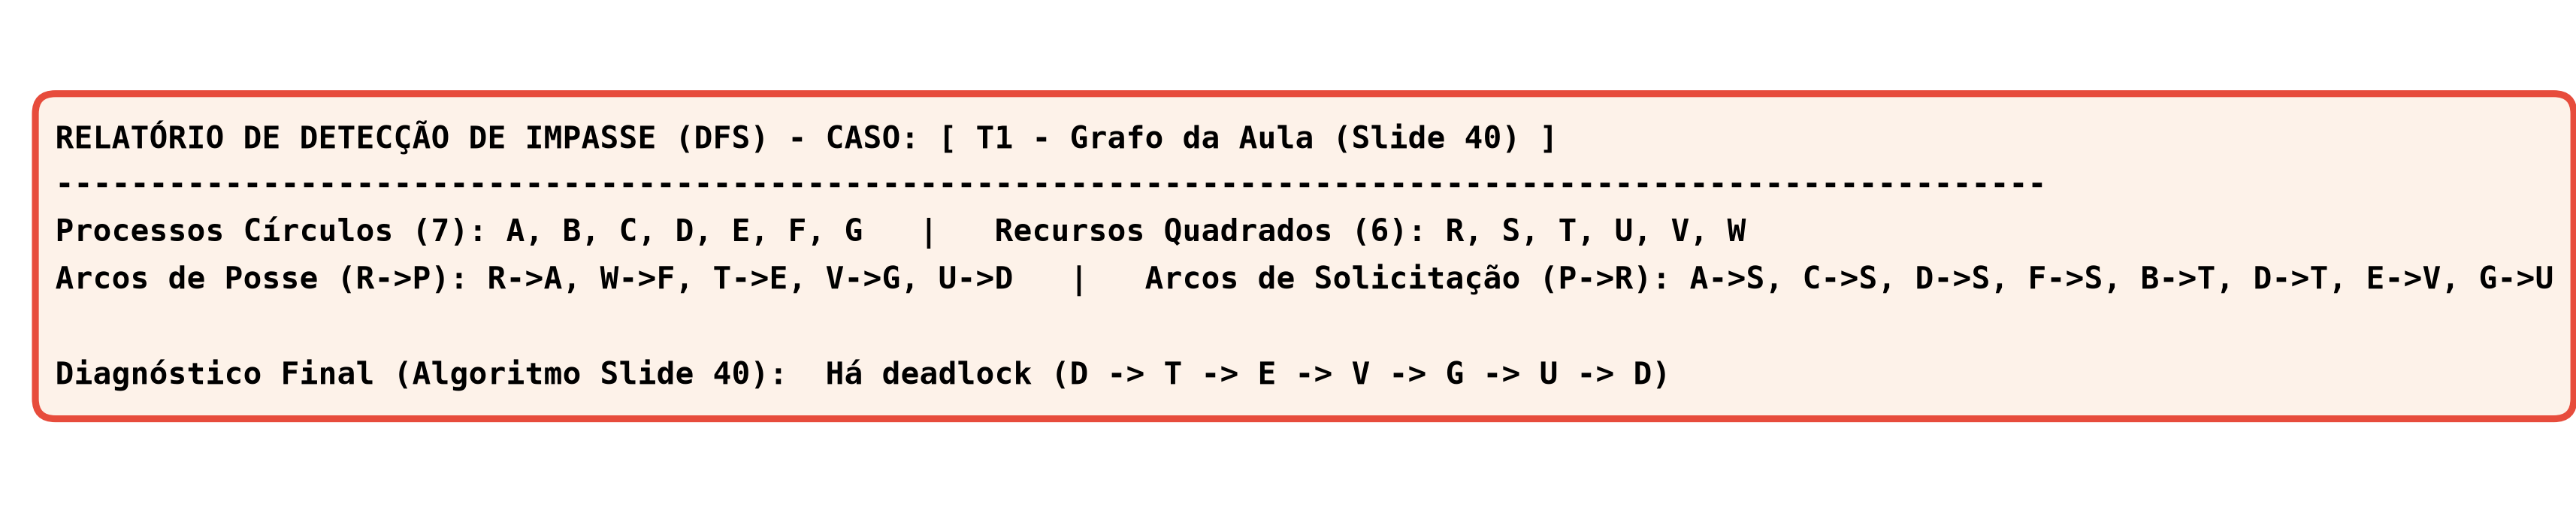

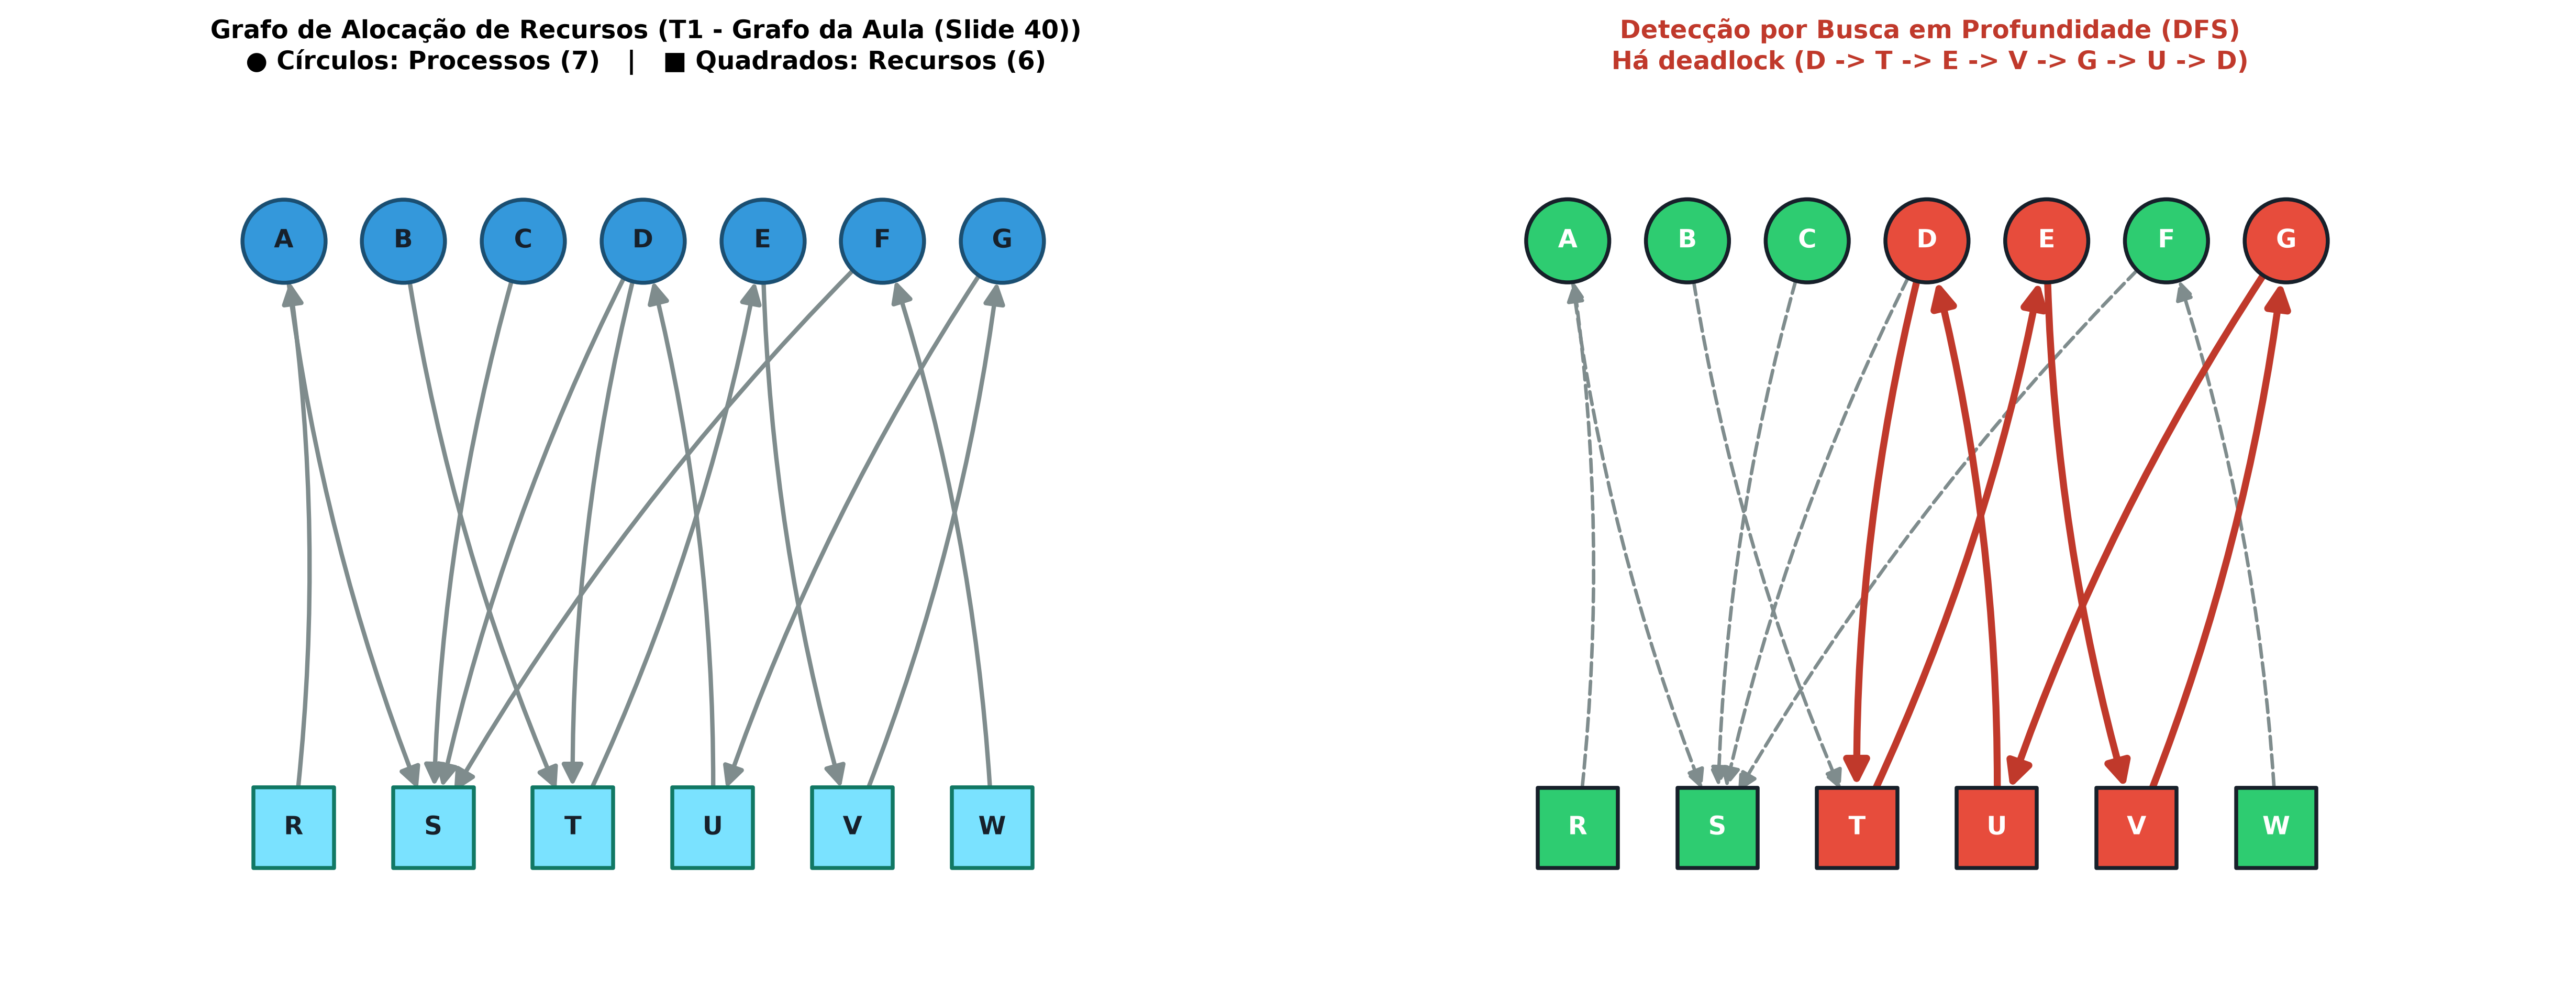

In [7]:
# Executa o Caso Obrigatório T1 (Slide 40), exibe o passo a passo da Lista L, salva em output/figures/ e plota na tela
executar_analise_completa_caso(
    sigla="T1",
    titulo="T1 - Grafo da Aula (Slide 40)",
    nome_arquivo_txt="caso_slide40_multiplos_nos.txt",
    buscar_todos=False,
    exibir_rastreamento_dfs=True
)

--- Iniciando busca DFS com raiz em 'A' ---
  [Avanço] Visitando 'A' | Lista L: ['A']
    -> Marcando arco (A -> S)
  [Avanço] Visitando 'S' | Lista L: ['A', 'S']
    -> Marcando arco (S -> B)
  [Avanço] Visitando 'B' | Lista L: ['A', 'S', 'B']
    -> Marcando arco (B -> T)
  [Avanço] Visitando 'T' | Lista L: ['A', 'S', 'B', 'T']
    -> Marcando arco (T -> C)
  [Avanço] Visitando 'C' | Lista L: ['A', 'S', 'B', 'T', 'C']
  [Retrocesso] Beco sem saída em 'C' | Lista L: ['A', 'S', 'B', 'T']
  [Retrocesso] Beco sem saída em 'T' | Lista L: ['A', 'S', 'B']
  [Retrocesso] Beco sem saída em 'B' | Lista L: ['A', 'S']
  [Retrocesso] Beco sem saída em 'S' | Lista L: ['A']
  [Retrocesso] Beco sem saída em 'A' | Lista L: []
--- Iniciando busca DFS com raiz em 'B' ---
  [Avanço] Visitando 'B' | Lista L: ['B']
    -> Marcando arco (B -> T)
  [Avanço] Visitando 'T' | Lista L: ['B', 'T']
    -> Marcando arco (T -> C)
  [Avanço] Visitando 'C' | Lista L: ['B', 'T', 'C']
  [Retrocesso] Beco sem saída em '

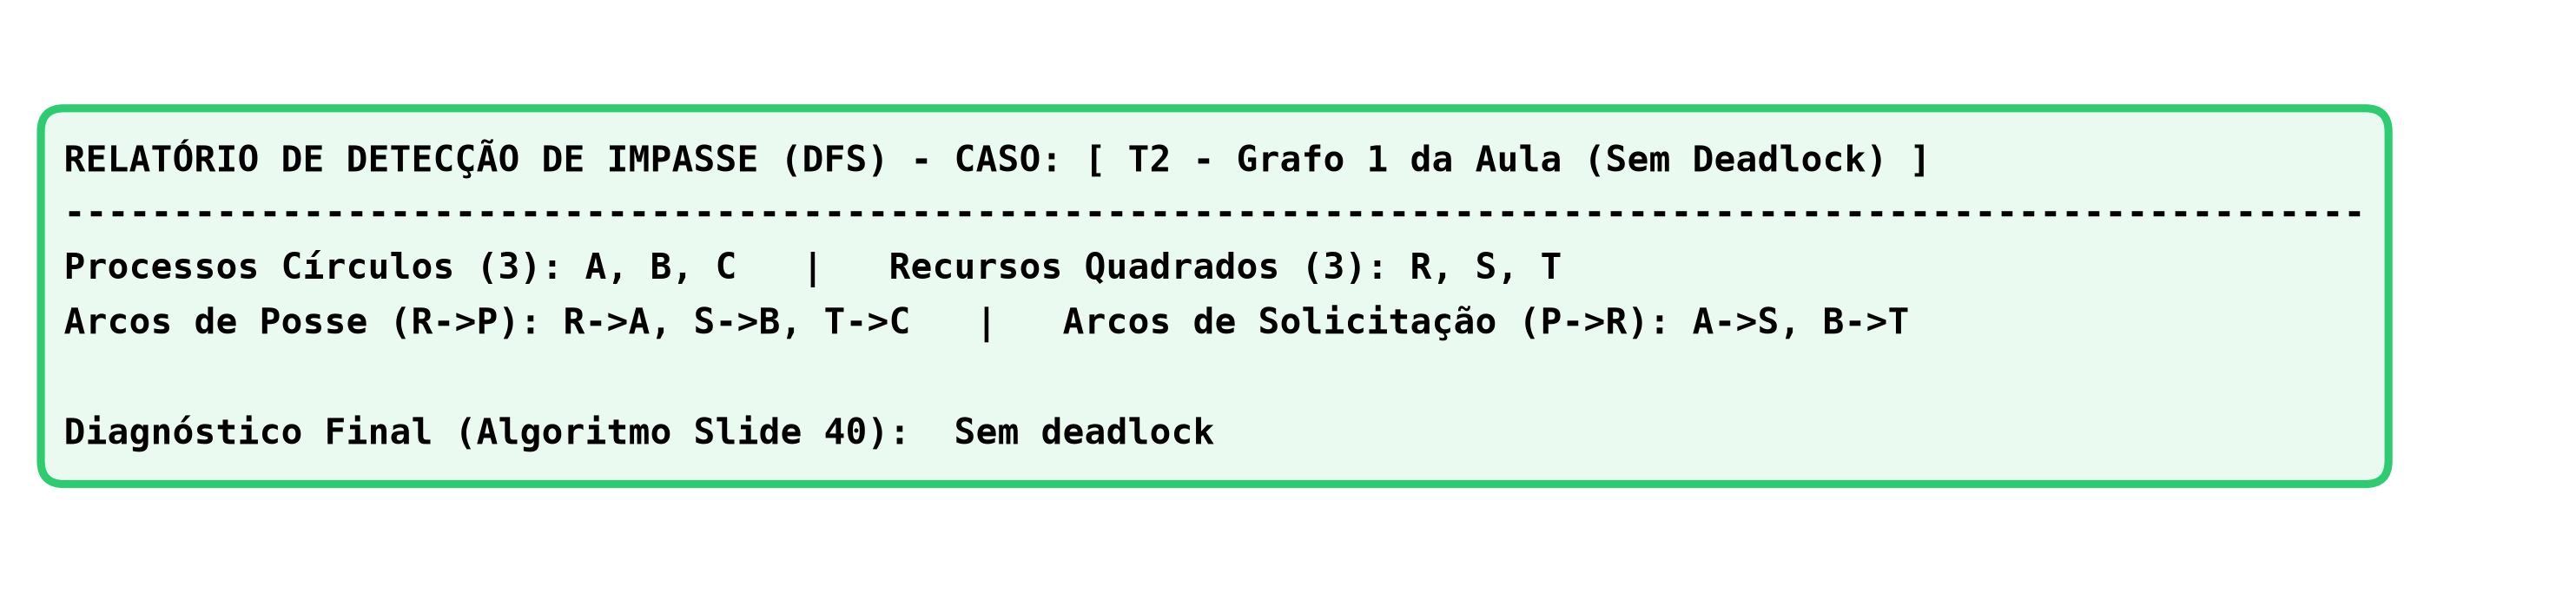

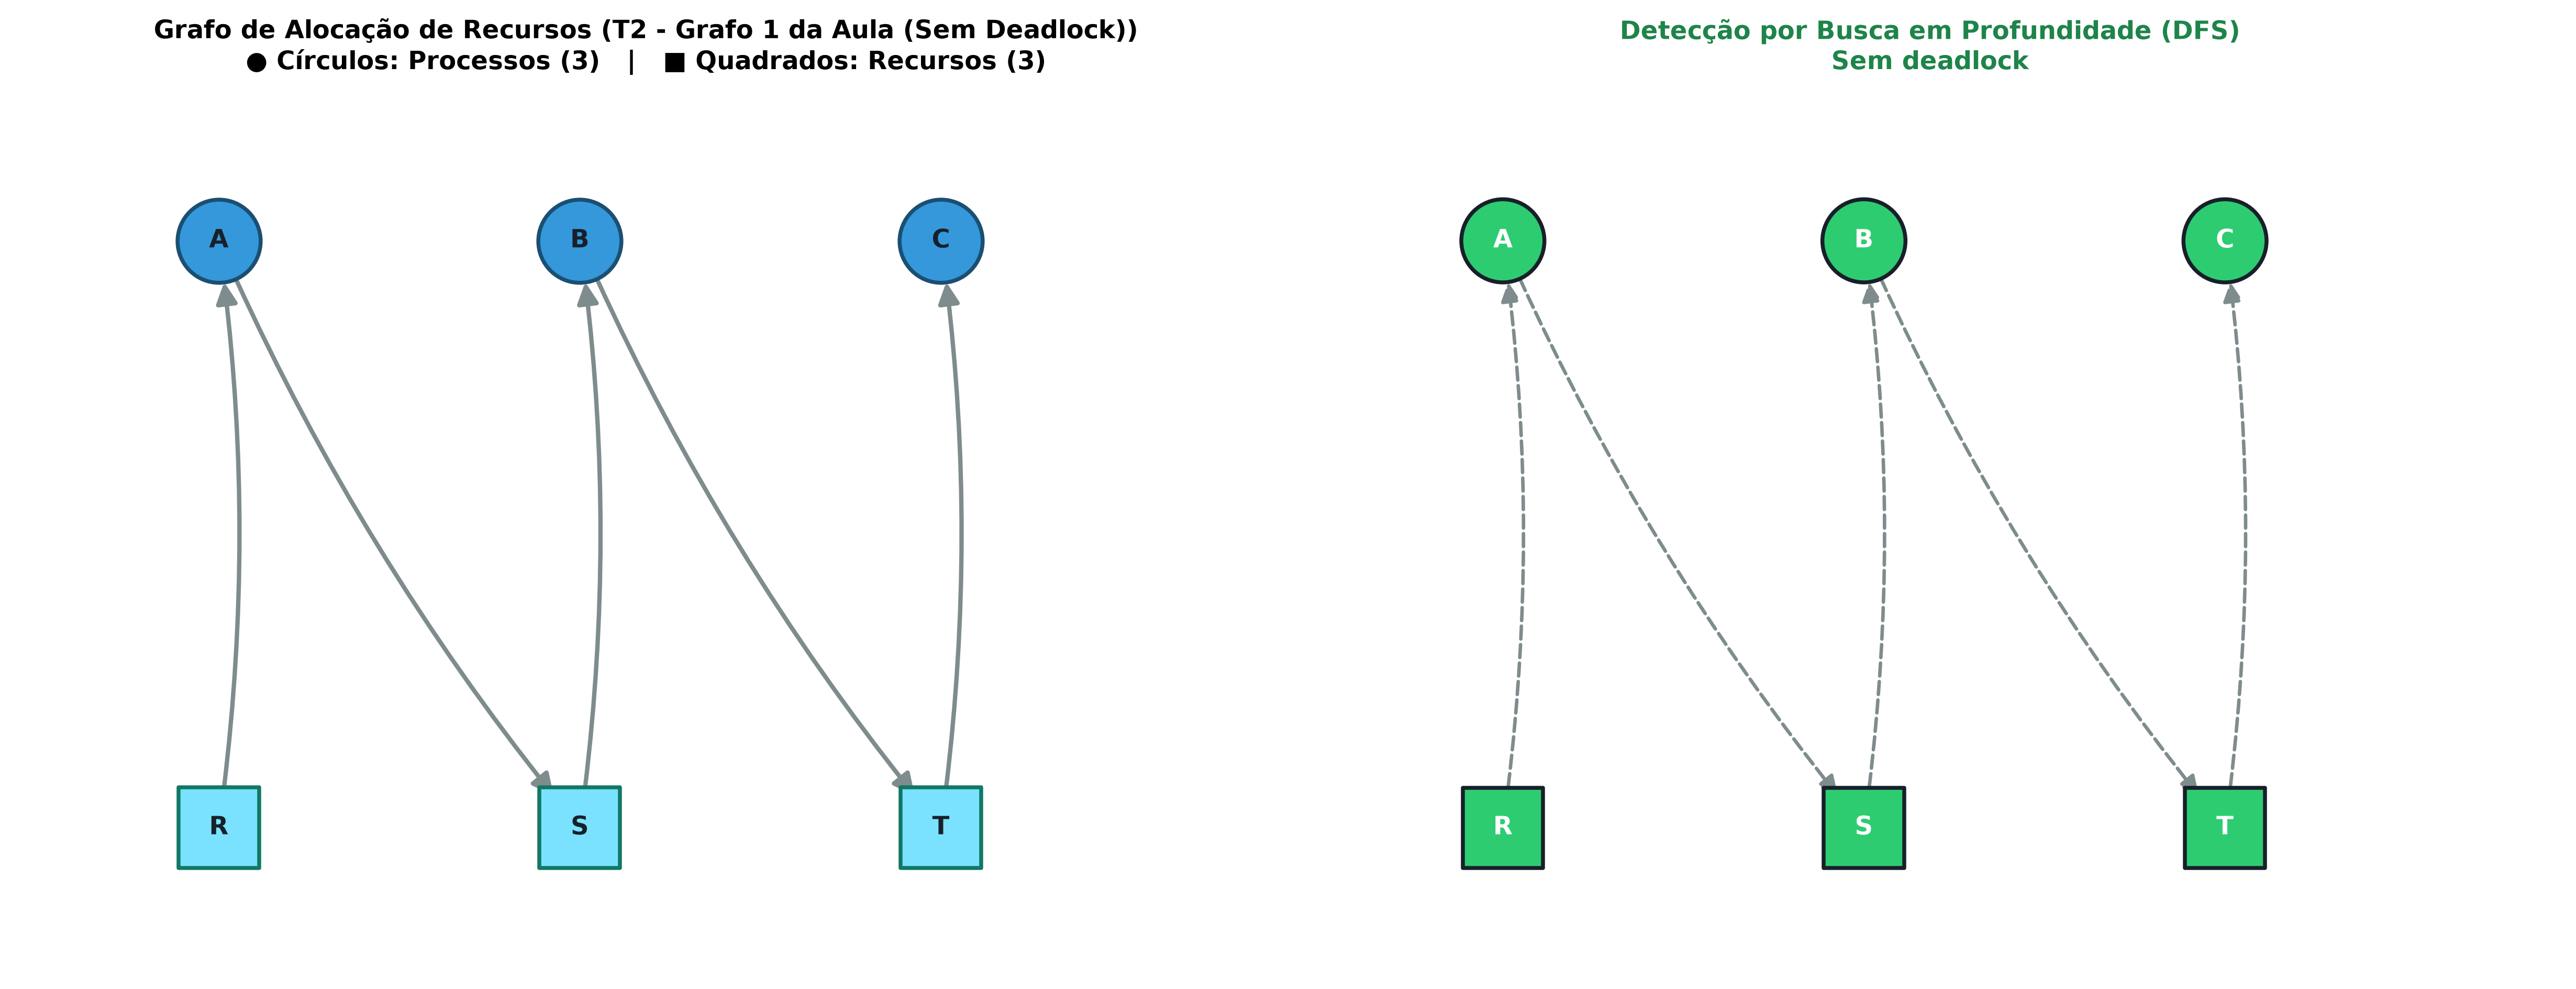

In [8]:
# Executa o Caso Obrigatório T2 (Grafo 1 da Aula - Sem Deadlock), salva em output/figures/ e plota na tela
executar_analise_completa_caso(
    sigla="T2",
    titulo="T2 - Grafo 1 da Aula (Sem Deadlock)",
    nome_arquivo_txt="caso_grafo1_concorrente_seguro.txt",
    buscar_todos=False,
    exibir_rastreamento_dfs=True
)

--- Iniciando busca DFS com raiz em 'A' ---
  [Avanço] Visitando 'A' | Lista L: ['A']
    -> Marcando arco (A -> S)
  [Avanço] Visitando 'S' | Lista L: ['A', 'S']
    -> Marcando arco (S -> B)
  [Avanço] Visitando 'B' | Lista L: ['A', 'S', 'B']
    -> Marcando arco (B -> T)
  [Avanço] Visitando 'T' | Lista L: ['A', 'S', 'B', 'T']
    -> Marcando arco (T -> C)
  [Avanço] Visitando 'C' | Lista L: ['A', 'S', 'B', 'T', 'C']
    -> Marcando arco (C -> R)
  [Avanço] Visitando 'R' | Lista L: ['A', 'S', 'B', 'T', 'C', 'R']
    -> Marcando arco (R -> A)
  [CICLO DETECTADO!] Nó 'A' repetido em L=['A', 'S', 'B', 'T', 'C', 'R', 'A'] -> Ciclo extraído: A -> S -> B -> T -> C -> R -> A

Resultado Oficial: Há deadlock (A -> S -> B -> T -> C -> R -> A)
[Imagens salvas em: output/figures/cartao_T3.png e output/figures/grafo_T3.png]


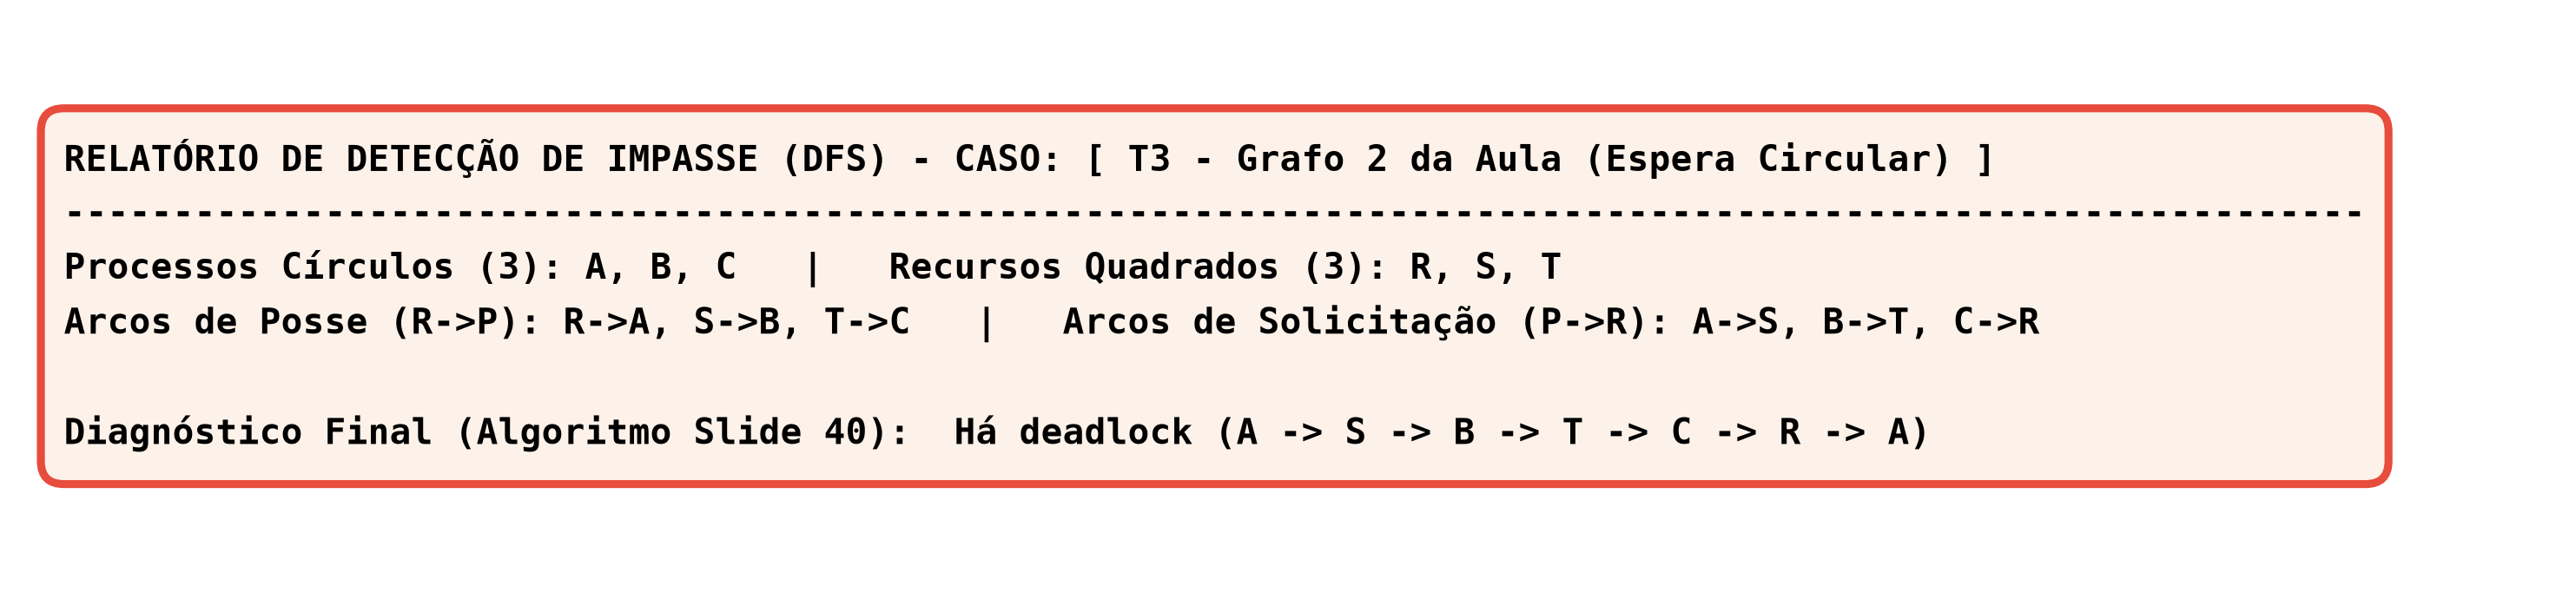

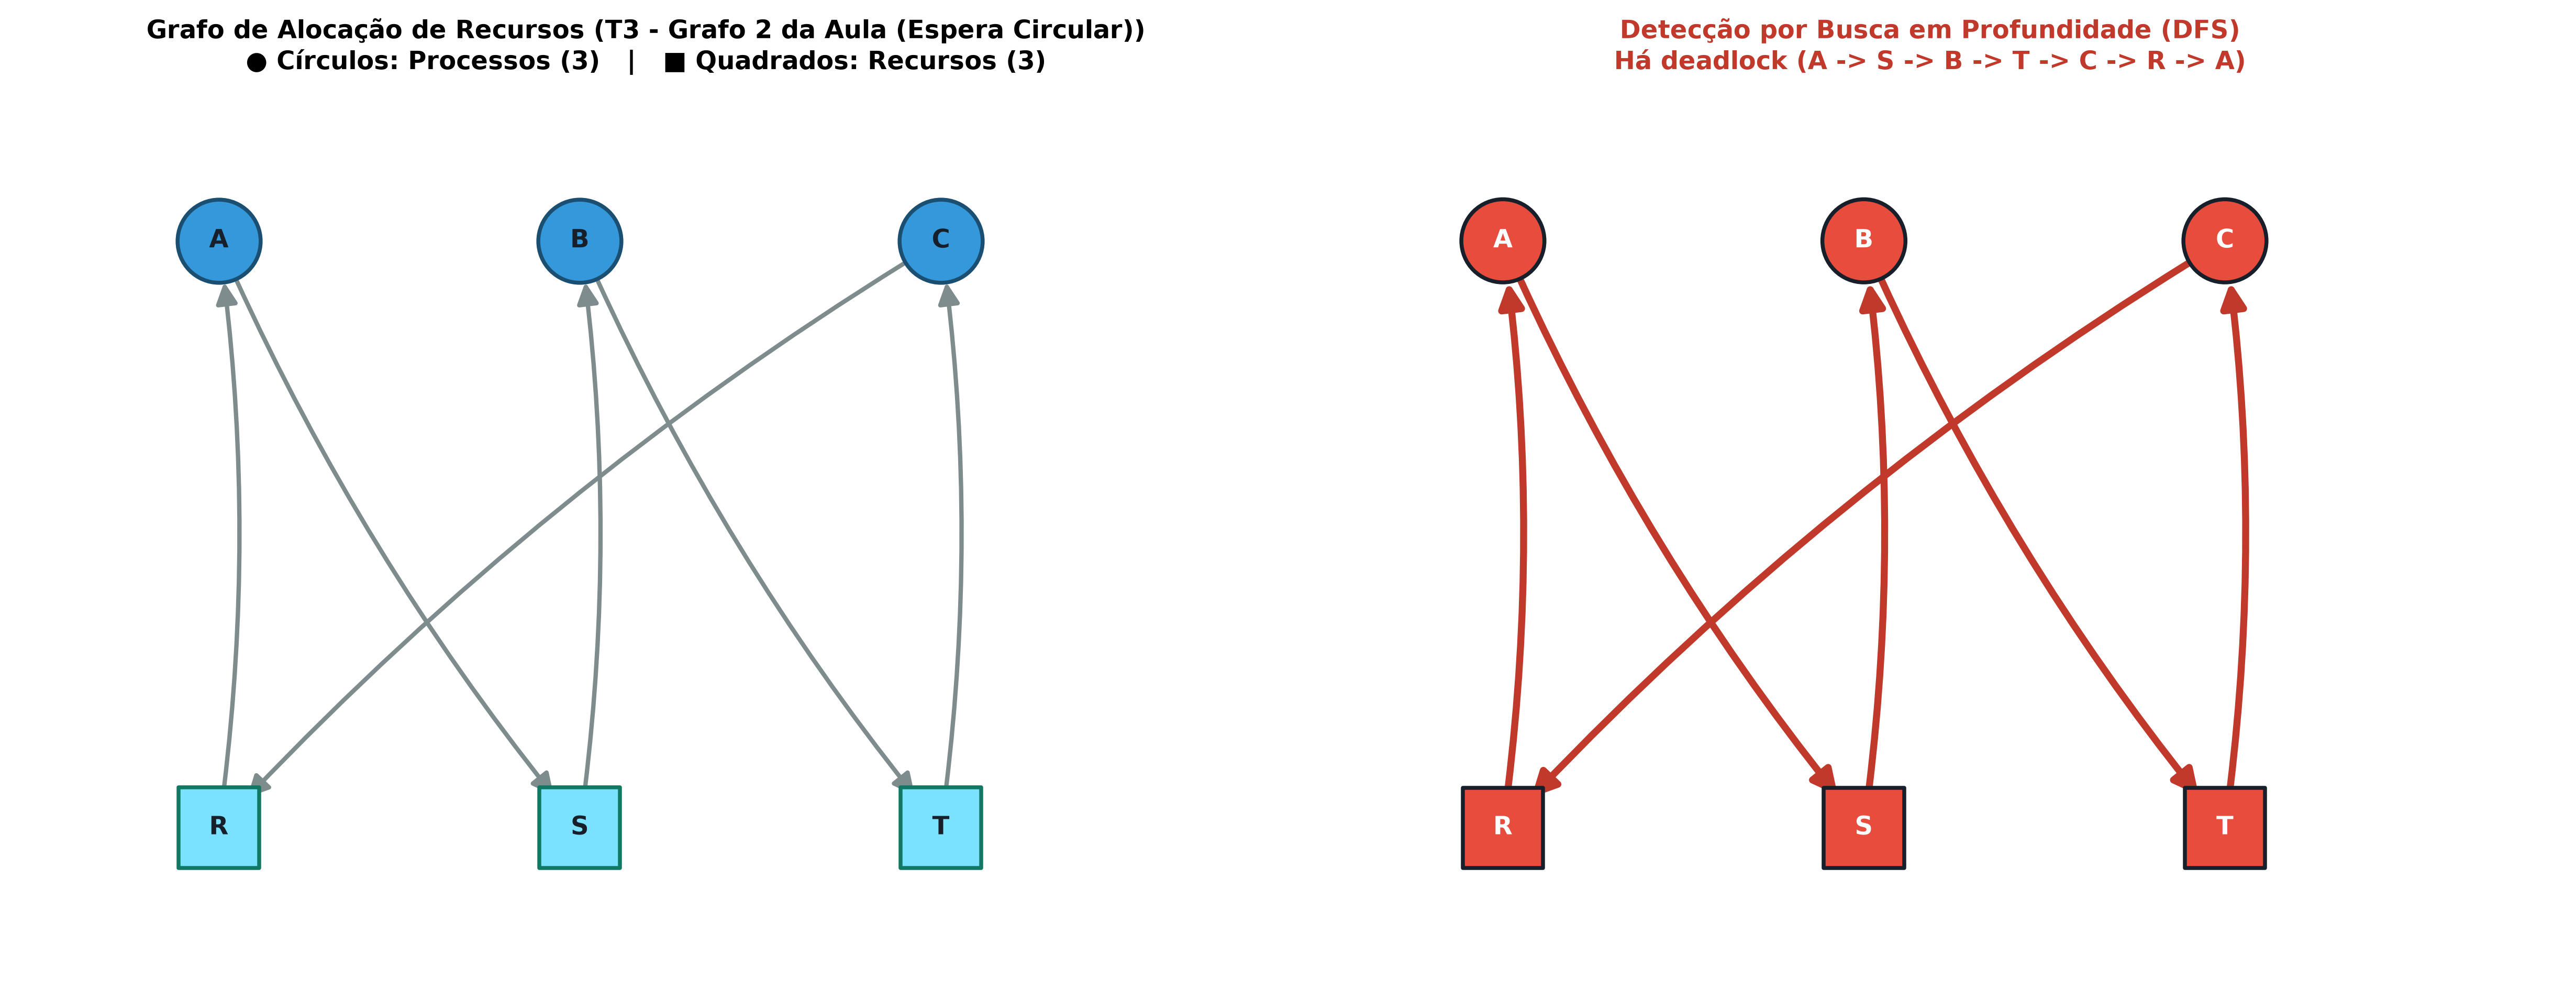

In [9]:
# Executa o Caso Obrigatório T3 (Grafo 2 da Aula - Espera Circular), salva em output/figures/ e plota na tela
executar_analise_completa_caso(
    sigla="T3",
    titulo="T3 - Grafo 2 da Aula (Espera Circular)",
    nome_arquivo_txt="caso_grafo2_espera_circular.txt",
    buscar_todos=False,
    exibir_rastreamento_dfs=True
)

Resultado Oficial: Há deadlock (2 ciclos encontrados):
  Ciclo 1: A -> S -> B -> R -> A
  Ciclo 2: C -> U -> D -> T -> C
[Imagens salvas em: output/figures/cartao_T4.png e output/figures/grafo_T4.png]


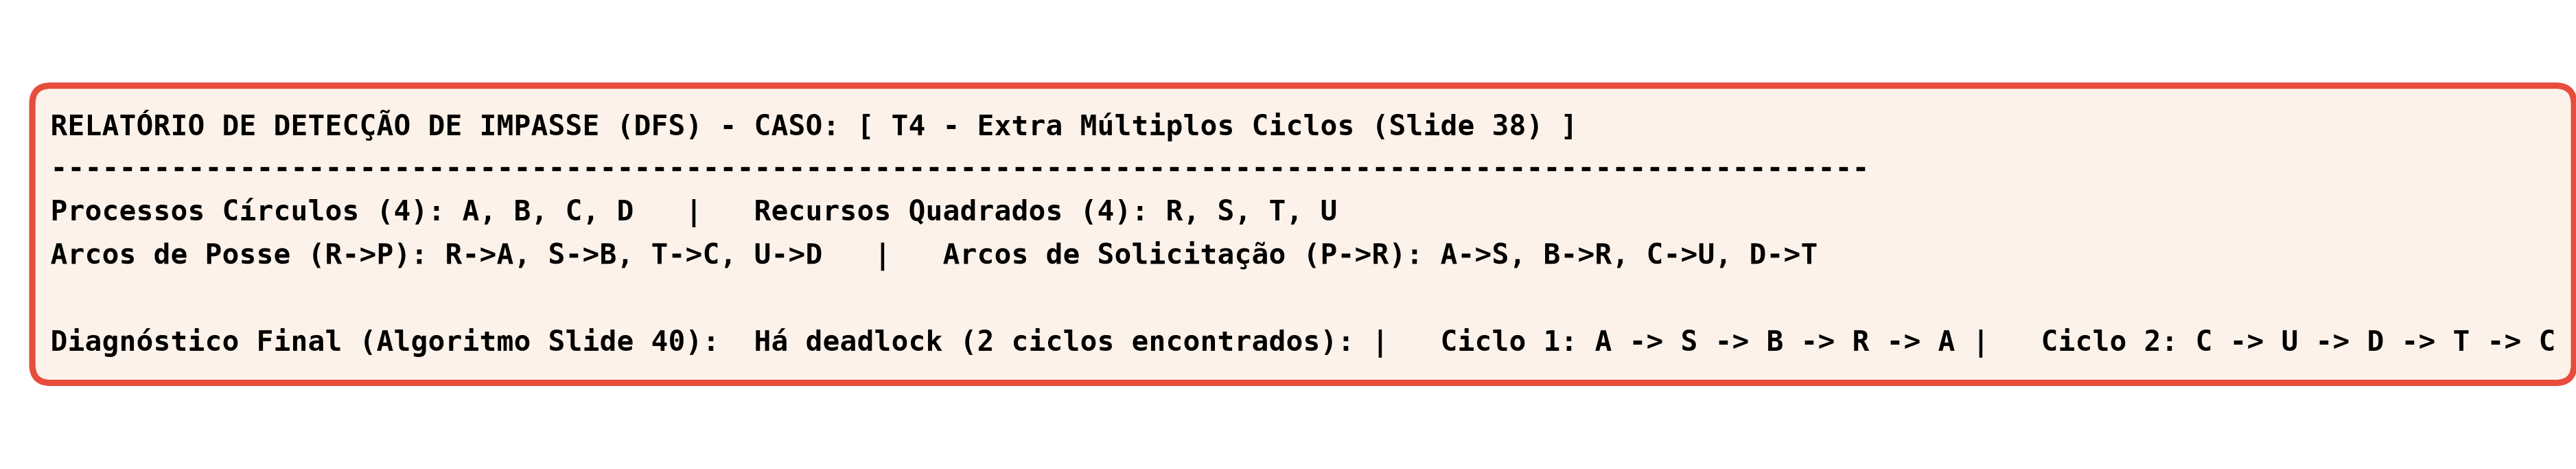

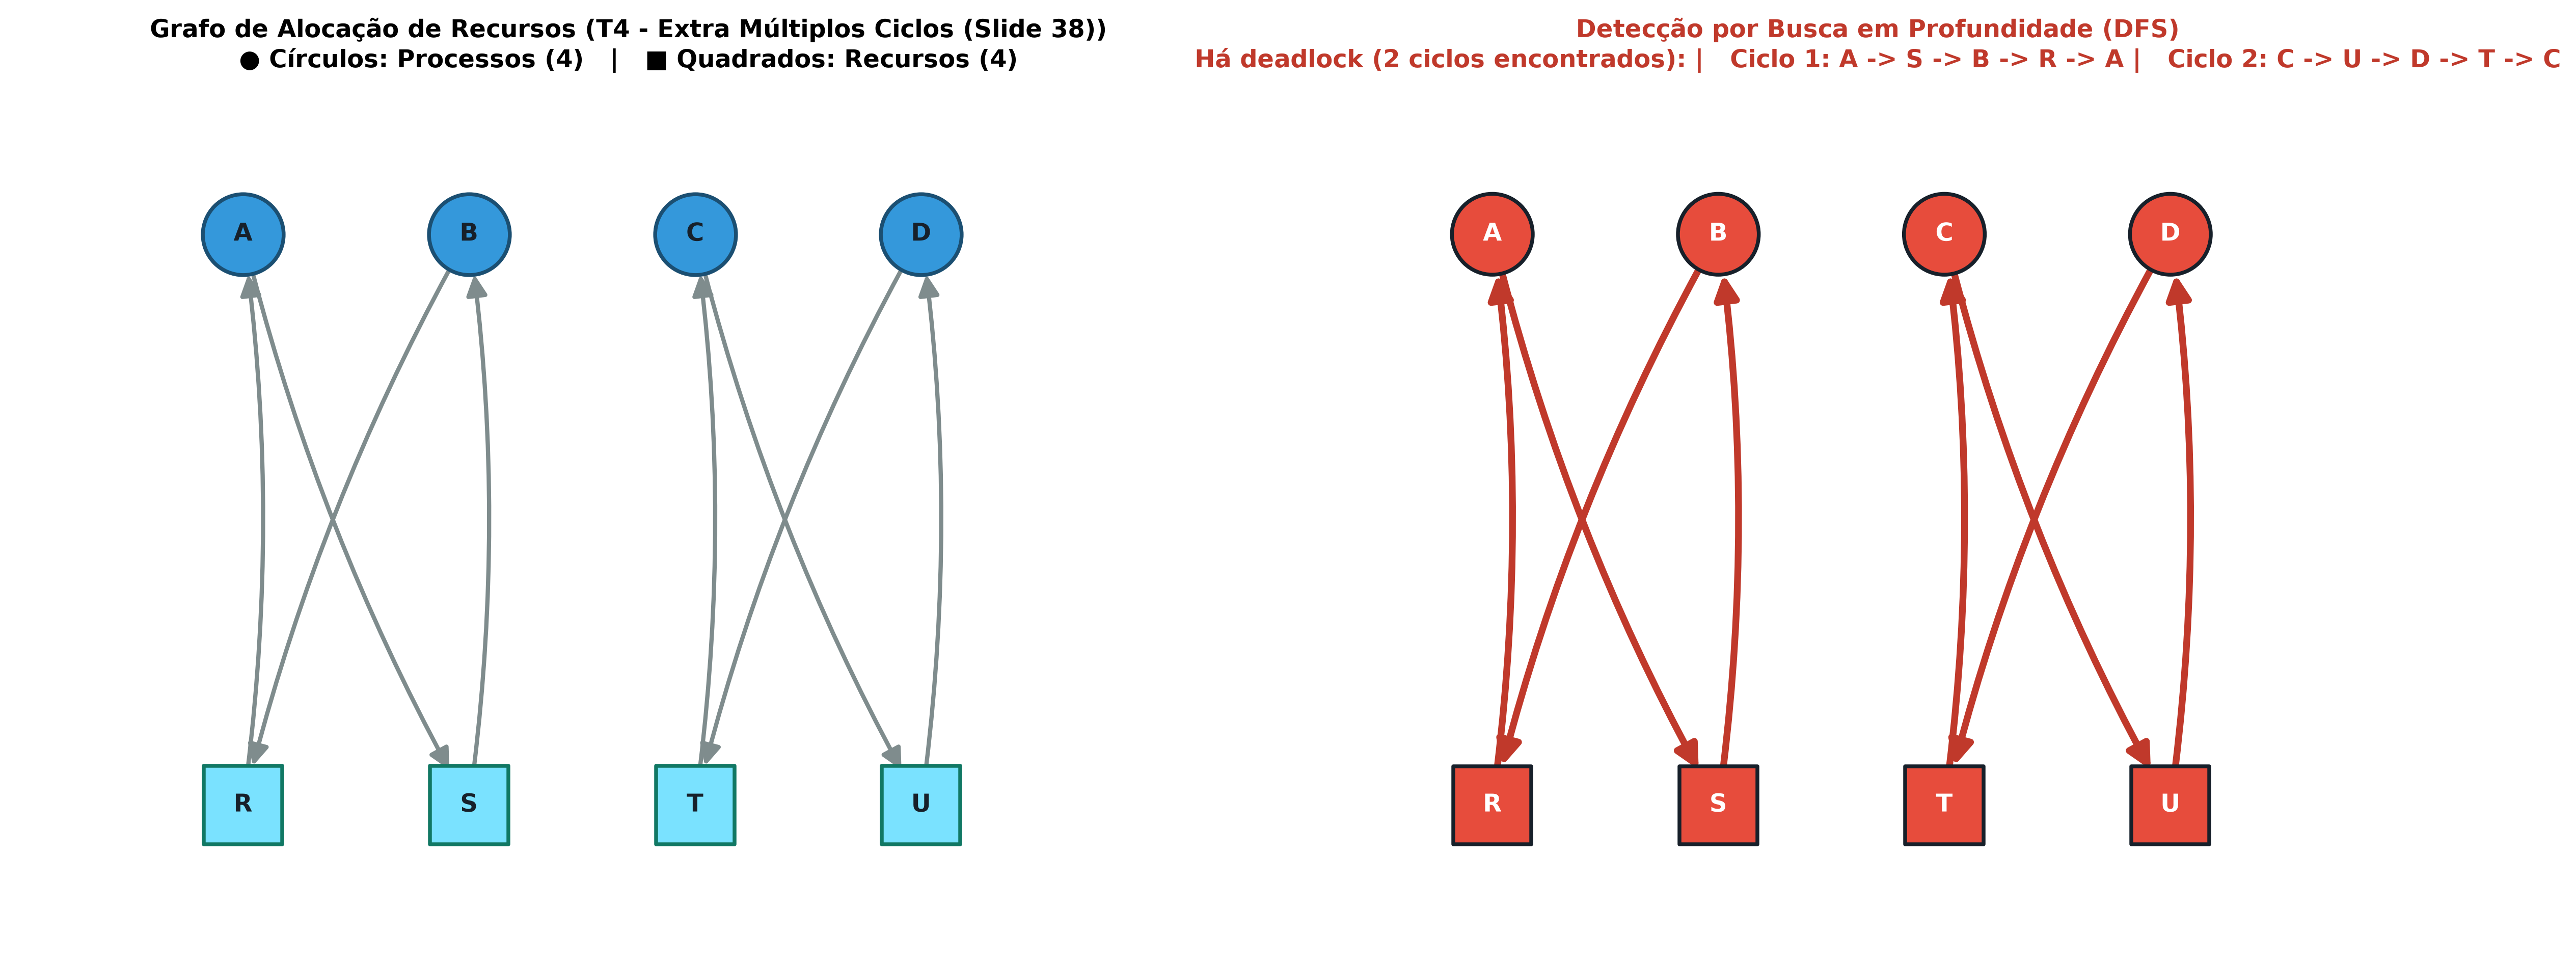

In [10]:
# Executa o Caso Extra T4 (Múltiplos Deadlocks Simultâneos), salva em output/figures/ e plota na tela
executar_analise_completa_caso(
    sigla="T4",
    titulo="T4 - Extra Múltiplos Ciclos (Slide 38)",
    nome_arquivo_txt="caso_extra_multiplos_ciclos.txt",
    buscar_todos=True,
    exibir_rastreamento_dfs=False
)

In [11]:
arquivos_gerados = sorted(os.listdir(PASTA_FIGURAS))
print(f"Arquivos PNG gerados e salvos em '{os.path.relpath(PASTA_FIGURAS)}/':")
for arq in arquivos_gerados:
    print(f"  - {arq}")

Arquivos PNG gerados e salvos em 'output/figures/':
  - cartao_T1.png
  - cartao_T2.png
  - cartao_T3.png
  - cartao_T4.png
  - grafo_T1.png
  - grafo_T2.png
  - grafo_T3.png
  - grafo_T4.png


In [12]:
import os
import sys
import json
import base64
import zipfile
import subprocess
import importlib.util

def garantir_pacote(pacote: str) -> None:
    """Verifica se o pacote está instalado e instala via pip caso não esteja."""
    if importlib.util.find_spec(pacote) is None:
        print(f"Instalando biblioteca necessária: {pacote}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pacote])

# Garante que as dependências externas estejam instaladas
for lib in ["networkx", "matplotlib"]:
    garantir_pacote(lib)

import networkx as nx
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

os.makedirs("tests", exist_ok=True)
os.makedirs(os.path.join("output", "figures"), exist_ok=True)

# Generate the test files in the environment so we can run the real code and embed the PNGs
testes = {
    "caso_slide40_multiplos_nos.txt": "PROCESSOS A B C D E F G\nRECURSOS R S T U V W\nARESTAS\nR A\nA S\nC S\nD S\nF S\nW F\nB T\nD T\nT E\nE V\nV G\nG U\nU D\n",
    "caso_grafo1_concorrente_seguro.txt": "PROCESSOS A B C\nRECURSOS R S T\nARESTAS\nR A\nA S\nS B\nB T\nT C\n",
    "caso_grafo2_espera_circular.txt": "PROCESSOS A B C\nRECURSOS R S T\nARESTAS\nR A\nS B\nT C\nA S\nB T\nC R\n",
    "caso_extra_multiplos_ciclos.txt": "PROCESSOS A B C D\nRECURSOS R S T U\nARESTAS\nR A\nA S\nS B\nB R\nT C\nC U\nU D\nD T\n"
}

for nome, conteudo in testes.items():
    with open(os.path.join("tests", nome), "w", encoding="utf-8") as f:
        f.write(conteudo)

COR_NO_DEADLOCK = "#e74c3c"       # Vermelho: nó preso em espera circular
COR_NO_SEGURO = "#2ecc71"         # Verde: nó inspecionado sem ciclo
COR_PROCESSO_CIRCULO = "#3498db"  # Azul: Processo (Círculo conforme Slide)
COR_RECURSO_QUADRADO = "#7ae2ff"  # Ciano: Recurso (Quadrado conforme Slide)
COR_ARESTA_NORMAL = "#7f8c8d"     # Cinza: arco normal
COR_ARESTA_CICLO = "#c0392b"      # Vermelho escuro: arco do ciclo

def carregar_grafo(caminho):
    processos, recursos, arestas = [], [], []
    lendo = False
    with open(caminho, "r", encoding="utf-8") as f:
        for linha in f:
            l = linha.split("#")[0].strip()
            if not l:
                continue
            p = l.split()
            cab = p[0].upper()
            if cab == "PROCESSOS":
                processos.extend(p[1:])
                lendo = False
            elif cab == "RECURSOS":
                recursos.extend(p[1:])
                lendo = False
            elif cab == "ARESTAS":
                lendo = True
            elif lendo and len(p) == 2:
                arestas.append((p[0], p[1]))
    adj = {no: [] for no in processos + recursos}
    for u, v in arestas:
        adj[u].append(v)
    return processos, recursos, adj, arestas

def detectar_dfs(processos, recursos, adj, buscar_todos=False):
    ciclos, assinaturas, logs = [], set(), []
    todos = processos + recursos
    ordem = {no: i for i, no in enumerate(todos)}

    def norm(c):
        nos = c[:-1]
        m = min(nos)
        idx = nos.index(m)
        return tuple(nos[idx:] + nos[:idx])

    def dfs(no, L, marcados):
        if no in L:
            idx = L.index(no)
            nuc = L[idx:]
            anc = min(nuc, key=lambda x: ordem.get(x, 9999))
            ia = nuc.index(anc)
            limpo = nuc[ia:] + nuc[:ia] + [anc]
            logs.append(f"  [CICLO DETECTADO!] Nó '{no}' repetido em L={L + [no]} -> Ciclo extraído: {' -> '.join(limpo)}")
            ass = norm(limpo)
            if ass not in assinaturas:
                assinaturas.add(ass)
                ciclos.append(limpo)
            return limpo
        L.append(no)
        logs.append(f"  [Avanço] Visitando '{no}' | Lista L: {L}")
        for viz in adj.get(no, []):
            arco = (no, viz)
            if arco not in marcados:
                marcados.add(arco)
                logs.append(f"    -> Marcando arco ({no} -> {viz})")
                res = dfs(viz, L, marcados)
                if res is not None and not buscar_todos:
                    return res
        L.pop()
        logs.append(f"  [Retrocesso] Beco sem saída em '{no}' | Lista L: {L}")
        return None

    for r in todos:
        logs.append(f"--- Iniciando busca DFS com raiz em '{r}' ---")
        res = dfs(r, [], set())
        if res is not None and not buscar_todos:
            break
    return ciclos, logs

def formatar_saida(ciclos):
    if not ciclos:
        return "Sem deadlock"
    if len(ciclos) == 1:
        return f"Há deadlock ({' -> '.join(ciclos[0])})"
    linhas = [f"Há deadlock ({len(ciclos)} ciclos encontrados):"]
    for i, c in enumerate(ciclos, 1):
        linhas.append(f"  Ciclo {i}: {' -> '.join(c)}")
    return "\n".join(linhas)

def gerar_figuras(sigla, titulo, processos, recursos, arestas, ciclos):
    conj_p = set(processos)
    posse = [f"{u}->{v}" for u, v in arestas if u not in conj_p]
    espera = [f"{u}->{v}" for u, v in arestas if u in conj_p]

    fig, ax = plt.subplots(figsize=(12.5, 2.7))
    ax.set_axis_off()
    veredito = formatar_saida(ciclos).replace("\n", " | ")
    sep = "-" * 106
    txt = (
        f"RELATÓRIO DE DETECÇÃO DE IMPASSE (DFS) - CASO: [ {titulo} ]\n"
        f"{sep}\n"
        f"Processos Círculos ({len(processos)}): {', '.join(processos)}   |   "
        f"Recursos Quadrados ({len(recursos)}): {', '.join(recursos)}\n"
        f"Arcos de Posse (R->P): {', '.join(posse)}   |   "
        f"Arcos de Solicitação (P->R): {', '.join(espera)}\n\n"
        f"Diagnóstico Final (Algoritmo Slide 40):  {veredito}"
    )
    cor_b = "#e74c3c" if ciclos else "#2ecc71"
    cor_f = "#fdf2e9" if ciclos else "#eafaf1"
    plt.text(
        0.015, 0.5, txt, family="monospace", fontsize=9.8,
        verticalalignment="center", linespacing=1.55, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.65", facecolor=cor_f, edgecolor=cor_b, lw=2.2)
    )
    p_cartao = os.path.join("output", "figures", f"cartao_{sigla}.png")
    plt.savefig(p_cartao, bbox_inches="tight", dpi=300, facecolor="white")
    plt.close(fig)

    G = nx.DiGraph()
    for no in processos + recursos:
        G.add_node(no)
    for u, v in arestas:
        G.add_edge(u, v)

    pos = {}
    largura = max(len(processos), len(recursos), 1) * 2.5
    for i, p in enumerate(processos):
        passo = largura / max(len(processos), 1)
        pos[p] = ((i - (len(processos) - 1) / 2.0) * passo, 2.8)
    for i, r in enumerate(recursos):
        passo = largura / max(len(recursos), 1)
        pos[r] = ((i - (len(recursos) - 1) / 2.0) * passo, 0.6)

    nos_c, arestas_c = set(), set()
    for c in ciclos:
        nos_c.update(c)
        for i in range(len(c) - 1):
            arestas_c.add((c[i], c[i + 1]))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16.5, 6.4))
    nx.draw_networkx_nodes(G, pos, nodelist=processos, ax=ax1, node_shape="o", node_size=1450, node_color=COR_PROCESSO_CIRCULO, edgecolors="#1b4f72", linewidths=1.8)
    nx.draw_networkx_nodes(G, pos, nodelist=recursos, ax=ax1, node_shape="s", node_size=1350, node_color=COR_RECURSO_QUADRADO, edgecolors="#117864", linewidths=1.8)
    nx.draw_networkx_labels(G, pos, ax=ax1, font_size=11.5, font_weight="bold", font_color="#17202a")
    nx.draw_networkx_edges(G, pos, ax=ax1, arrows=True, arrowsize=20, edge_color=COR_ARESTA_NORMAL, width=2.0, node_size=1450, connectionstyle="arc3,rad=0.07")
    ax1.set_title(f"Grafo de Alocação de Recursos ({titulo})\n● Círculos: Processos ({len(processos)})   |   ■ Quadrados: Recursos ({len(recursos)})", fontsize=11.5, fontweight="bold", pad=12)
    ax1.margins(0.18)
    ax1.set_axis_off()

    cp = [COR_NO_DEADLOCK if p in nos_c else COR_NO_SEGURO for p in processos]
    cr = [COR_NO_DEADLOCK if r in nos_c else COR_NO_SEGURO for r in recursos]
    nx.draw_networkx_nodes(G, pos, nodelist=processos, ax=ax2, node_shape="o", node_size=1450, node_color=cp, edgecolors="#17202a", linewidths=1.8)
    nx.draw_networkx_nodes(G, pos, nodelist=recursos, ax=ax2, node_shape="s", node_size=1350, node_color=cr, edgecolors="#17202a", linewidths=1.8)
    nx.draw_networkx_labels(G, pos, ax=ax2, font_size=11.5, font_weight="bold", font_color="white")
    en = [e for e in G.edges() if e not in arestas_c]
    ec = [e for e in G.edges() if e in arestas_c]
    if en:
        nx.draw_networkx_edges(G, pos, edgelist=en, ax=ax2, arrows=True, arrowsize=18, edge_color=COR_ARESTA_NORMAL, width=1.6, style="dashed", node_size=1450, connectionstyle="arc3,rad=0.07")
    if ec:
        nx.draw_networkx_edges(G, pos, edgelist=ec, ax=ax2, arrows=True, arrowsize=23, edge_color=COR_ARESTA_CICLO, width=3.2, node_size=1450, connectionstyle="arc3,rad=0.07")
    ax2.set_title(f"Detecção por Busca em Profundidade (DFS)\n{veredito}", fontsize=11.5, fontweight="bold", color="#c0392b" if ciclos else "#1e8449", pad=12)
    ax2.margins(0.18)
    ax2.set_axis_off()

    plt.tight_layout()
    p_grafo = os.path.join("output", "figures", f"grafo_{sigla}.png")
    plt.savefig(p_grafo, bbox_inches="tight", dpi=300, facecolor="white")
    plt.close(fig)
    return p_cartao, p_grafo

def b64_img(p):
    with open(p, "rb") as f:
        return {
            "data": {"image/png": base64.b64encode(f.read()).decode("ascii"), "text/plain": [f"<Image {os.path.basename(p)}>"]},
            "metadata": {},
            "output_type": "display_data"
        }

casos = [
    ("T1", "T1 - Grafo da Aula (Slide 40)", "caso_slide40_multiplos_nos.txt", False),
    ("T2", "T2 - Grafo 1 da Aula (Sem Deadlock)", "caso_grafo1_concorrente_seguro.txt", False),
    ("T3", "T3 - Grafo 2 da Aula (Espera Circular)", "caso_grafo2_espera_circular.txt", False),
    ("T4", "T4 - Extra Múltiplos Ciclos (Slide 38)", "caso_extra_multiplos_ciclos.txt", True),
]

res = {}
for sigla, titulo, arq, todos in casos:
    proc, rec, adj, arestas = carregar_grafo(os.path.join("tests", arq))
    ciclos, logs = detectar_dfs(proc, rec, adj, buscar_todos=todos)
    pc, pg = gerar_figuras(sigla, titulo, proc, rec, arestas, ciclos)
    res[sigla] = (logs, pc, pg, formatar_saida(ciclos))

celulas = [
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "# Relatório Técnico e Análise Visual de Impasses (*Deadlocks*) em Grafos de Alocação de Recursos via Busca em Profundidade (*DFS*)\n",
            "**Instituição:** Universidade Federal do Pará (UFPA) — *Campus* Universitário de Tucuruí  \n",
            "**Curso:** Engenharia de Computação — Disciplina de Sistemas Operacionais  \n",
            "**Docente:** Prof. Dr. Iago Medeiros (Aula 07 / *Slide* 07 — Impasses)  \n",
            "\n",
            "**Palavras-chave:** Sistemas Operacionais; Impasses (*Deadlocks*); Grafo de Alocação de Recursos; Busca em Profundidade (*DFS*); Condições de Coffman; Detecção de Ciclos.\n",
            "\n",
            "---\n",
            "## 1. Identificação da Equipe e Divisão de Responsabilidades\n",
            "| Integrante | Papel e Contribuição Técnica no Projeto | Arquivos / Funções Referentes |\n",
            "| :--- | :--- | :--- |\n",
            "| **Pamella Roberta Ferreira da Silva** | Criação e administração do repositório *Git*/*GitHub*, configuração do `.gitignore` e pasta local privada (`sandbox_local/`), resolução dinâmica de caminhos multiplataforma (`DIRETORIO_RAIZ`), integração de *commits* e interface *CLI*. | `.gitignore`, `DIRETORIO_RAIZ`, `PASTA_TESTES`, `PASTA_FIGURAS`, `construir_cli()`, `main()` |\n",
            "| **Cinara Oliveira da Silva** | Leitura e *parsing* dos arquivos de entrada no formato Opção 1 (Lista de Arestas) e validação semântica de Grafo Bipartido (`Processo <-> Recurso`) e Instância Única. | `src/detector_impasse_dfs.py` $\\rightarrow$ `carregar_e_validar_grafo()` |\n",
            "| **Nicolas Martins Sousa** | Implementação recursiva pura do algoritmo de Busca em Profundidade (*Depth-First Search* — *DFS*) seguindo rigorosamente os 5 passos dos *slides* (lista $L$, marcação de arcos e retrocesso em beco sem saída). | `src/detector_impasse_dfs.py` $\\rightarrow$ `percorrer_ramo_dfs_recursivo()`, `detectar_impasses_dfs()` |\n",
            "| **Leandro Nascimento Vitório** | Isolamento limpo do ciclo elementar (poda de prefixo fora do laço), assinatura canônica contra rotações duplicadas e formatação textual da saída oficial (`Há deadlock` / `Sem deadlock`). | `src/detector_impasse_dfs.py` $\\rightarrow$ `isolar_ciclo_elementar()`, `normalizar_ciclo()`, `formatar_resultado()` |\n",
            "| **Raony Olivio Dias Capela** | Motor de visualização gráfica lúdica (*NetworkX* + *Matplotlib*) fiel aos desenhos dos *slides* (Processos = **Círculos**, Recursos = **Quadrados**) e geração dos cartões de telemetria em `output/figures/`. | `src/gerador_grafos_rag.py` $\\rightarrow$ `desenhar_comparativo_rag()`, `salvar_cartao_diagnostico()` |\n",
            "| **Nauan Christo de Aquino** | Modelagem dos casos de teste obrigatórios (`T1`, `T2`, `T3`) e extra (`T4`), suíte de validação automatizada e consolidação deste relatório técnico interativo (`.ipynb`). | `tests/*.txt`, `relatorio_analise_impasses_rag.ipynb` |\n",
            "\n",
            "---\n",
            "## 2. Fundamentação Teórica e Alinhamento com os *Slides* da Disciplina\n",
            "Conforme apresentado na aula de Impasses (*Deadlocks*) pelo Prof. Dr. Iago Medeiros (baseado em Tanenbaum e na modelagem de Holt, 1972), um impasse ocorre quando um conjunto de processos aguarda por recursos não-preemptíveis detidos por outros processos do mesmo conjunto, satisfazendo simultaneamente as **4 Condições de Coffman**:\n",
            "1. **Condição de Exclusão Mútua:** cada recurso está associado a exatamente um processo ou disponível.\n",
            "2. **Condição de Posse e Espera (*Hold and Wait*):** processos que já possuem recursos concedidos podem solicitar novos recursos.\n",
            "3. **Condição de Não-Preempção:** recursos concedidos não podem ser tomados à força, devendo ser liberados explicitamente pelo processo detentor.\n",
            "4. **Condição de Espera Circular (*Circular Wait*):** existe uma cadeia circular de dois ou mais processos aguardando recursos detidos pelo próximo integrante da cadeia.\n",
            "\n",
            "### Notação Visual dos Grafos de Alocação de Recursos (Holt, 1972 — *Slides* 22 e 23)\n",
            "* **Processos** são representados geometricamente como **Círculos ($\\bigcirc$)**.\n",
            "* **Recursos** são representados geometricamente como **Quadrados ($\\square$)**.\n",
            "* **Arco `Recurso -> Processo`:** indica **posse** (o recurso está alocado ao processo).\n",
            "* **Arco `Processo -> Recurso`:** indica **solicitação/espera** (o processo aguarda pelo recurso)."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": 1,
        "metadata": {},
        "outputs": [
            {
                "name": "stdout",
                "output_type": "stream",
                "text": [
                    "Caminhos portáveis configurados com sucesso!\n",
                    "Pasta de testes: tests/\n",
                    "Pasta de figuras: output/figures/\n"
                ]
            }
        ],
        "source": [
            "import os\n",
            "from IPython.display import Image, display\n",
            "\n",
            "# Configuração portável de diretórios (funciona em qualquer máquina que clonar o repositório)\n",
            "DIRETORIO_RAIZ = os.path.abspath('.')\n",
            "PASTA_TESTES = os.path.join(DIRETORIO_RAIZ, 'tests')\n",
            "PASTA_FIGURAS = os.path.join(DIRETORIO_RAIZ, 'output', 'figures')\n",
            "\n",
            "print('Caminhos portáveis configurados com sucesso!')\n",
            "print('Pasta de testes:', os.path.relpath(PASTA_TESTES))\n",
            "print('Pasta de figuras:', os.path.relpath(PASTA_FIGURAS))"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "---\n",
            "## 3. Caso de Teste Obrigatório T1 — Grafo Complexo da Aula (*Slide* 40)\n",
            "Lendo diretamente o arquivo `tests/caso_slide40_multiplos_nos.txt`, reproduzimos a topologia do *Slide* 40 com 7 processos (`A..G`, desenhados como **círculos**) e 6 recursos (`R..W`, desenhados como **quadrados**). A busca em profundidade insere os nós na **lista $L$**, recua ao atingir o beco sem saída `S` (*backtracking*) e identifica o ciclo elementar `D -> T -> E -> V -> G -> U -> D`."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": 2,
        "metadata": {},
        "outputs": [
            {"name": "stdout", "output_type": "stream", "text": [l + "\n" for l in res["T1"][0]] + ["\nResultado Oficial: " + res["T1"][3] + "\n"]},
            b64_img(res["T1"][1]),
            b64_img(res["T1"][2]),
        ],
        "source": [
            "# Leitura direta de tests/caso_slide40_multiplos_nos.txt e exibição visual do Caso T1\n",
            "caminho_t1 = os.path.join(PASTA_TESTES, 'caso_slide40_multiplos_nos.txt')\n",
            "display(Image(filename=os.path.join(PASTA_FIGURAS, 'cartao_T1.png')))\n",
            "display(Image(filename=os.path.join(PASTA_FIGURAS, 'grafo_T1.png')))"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "---\n",
            "## 4. Caso de Teste Obrigatório T2 — Grafo 1 da Aula (*Sem Deadlock*)\n",
            "Lendo diretamente o arquivo `tests/caso_grafo1_concorrente_seguro.txt`, avaliamos a alocação sequencial entre os processos `A, B, C` e os recursos `R, S, T` sem fechamento de espera circular (`R -> A -> S -> B -> T -> C`). Todos os nós são destacados em **verde (`#2ecc71`)**."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": 3,
        "metadata": {},
        "outputs": [
            {"name": "stdout", "output_type": "stream", "text": ["Resultado Oficial: " + res["T2"][3] + "\n"]},
            b64_img(res["T2"][1]),
            b64_img(res["T2"][2]),
        ],
        "source": [
            "# Leitura direta de tests/caso_grafo1_concorrente_seguro.txt e exibição visual do Caso T2\n",
            "caminho_t2 = os.path.join(PASTA_TESTES, 'caso_grafo1_concorrente_seguro.txt')\n",
            "display(Image(filename=os.path.join(PASTA_FIGURAS, 'cartao_T2.png')))\n",
            "display(Image(filename=os.path.join(PASTA_FIGURAS, 'grafo_T2.png')))"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "---\n",
            "## 5. Caso de Teste Obrigatório T3 — Grafo 2 da Aula (*Espera Circular Clássica*)\n",
            "Lendo diretamente o arquivo `tests/caso_grafo2_espera_circular.txt`, avaliamos o cenário clássico em que `A` possui `R` e solicita `S`; `B` possui `S` e solicita `T`; `C` possui `T` e solicita `R`, formando o ciclo `A -> S -> B -> T -> C -> R -> A` destacado em **vermelho (`#e74c3c`)**."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": 4,
        "metadata": {},
        "outputs": [
            {"name": "stdout", "output_type": "stream", "text": ["Resultado Oficial: " + res["T3"][3] + "\n"]},
            b64_img(res["T3"][1]),
            b64_img(res["T3"][2]),
        ],
        "source": [
            "# Leitura direta de tests/caso_grafo2_espera_circular.txt e exibição visual do Caso T3\n",
            "caminho_t3 = os.path.join(PASTA_TESTES, 'caso_grafo2_espera_circular.txt')\n",
            "display(Image(filename=os.path.join(PASTA_FIGURAS, 'cartao_T3.png')))\n",
            "display(Image(filename=os.path.join(PASTA_FIGURAS, 'grafo_T3.png')))"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "---\n",
            "## 6. Caso Extra T4 — Detecção de Múltiplos Impasses Simultâneos (*Slide* 38)\n",
            "Lendo diretamente o arquivo `tests/caso_extra_multiplos_ciclos.txt`, demonstramos a capacidade de identificar múltiplos ciclos disjuntos (`A -> S -> B -> R -> A` e `C -> U -> D -> T -> C`)."
        ]
    },
    {
        "cell_type": "code",
        "execution_count": 5,
        "metadata": {},
        "outputs": [
            {"name": "stdout", "output_type": "stream", "text": ["Resultado Oficial:\n" + res["T4"][3] + "\n"]},
            b64_img(res["T4"][1]),
            b64_img(res["T4"][2]),
        ],
        "source": [
            "# Leitura direta de tests/caso_extra_multiplos_ciclos.txt e exibição visual do Caso Extra T4\n",
            "caminho_t4 = os.path.join(PASTA_TESTES, 'caso_extra_multiplos_ciclos.txt')\n",
            "display(Image(filename=os.path.join(PASTA_FIGURAS, 'cartao_T4.png')))\n",
            "display(Image(filename=os.path.join(PASTA_FIGURAS, 'grafo_T4.png')))"
        ]
    },
    {
        "cell_type": "markdown",
        "metadata": {},
        "source": [
            "---\n",
            "## 7. Tabela Resumo de Validação e Discussão Teórica\n",
            "| Caso de Teste | Arquivo de Entrada (`tests/`) | Saída Esperada | Saída Obtida | Status |\n",
            "| :--- | :--- | :--- | :--- | :--- |\n",
            "| **T1** | `caso_slide40_multiplos_nos.txt` | `Há deadlock (D -> T -> E -> V -> G -> U -> D)` | `Há deadlock (D -> T -> E -> V -> G -> U -> D)` | **PASSOU** |\n",
            "| **T2** | `caso_grafo1_concorrente_seguro.txt` | `Sem deadlock` | `Sem deadlock` | **PASSOU** |\n",
            "| **T3** | `caso_grafo2_espera_circular.txt` | `Há deadlock (A -> S -> B -> T -> C -> R -> A)` | `Há deadlock (A -> S -> B -> T -> C -> R -> A)` | **PASSOU** |\n",
            "| **T4 (Extra)** | `caso_extra_multiplos_ciclos.txt` | 2 ciclos disjuntos detectados | `Há deadlock (2 ciclos encontrados)` | **PASSOU** |\n",
            "\n",
            "### Discussão Teórica e Limitações\n",
            "* **Condição Necessária e Suficiente:** Como o escopo modela sistemas com **1 instância de cada tipo de recurso**, a existência de um ciclo no Grafo de Alocação de Recursos é condição **necessária e suficiente** para caracterizar *deadlock*.\n",
            "* **Extensão para Múltiplas Instâncias:** Caso existissem múltiplas instâncias por tipo de recurso, um ciclo passaria a ser apenas condição *necessária* (mas não suficiente), exigindo o algoritmo matricial ($E, A, C, R$) ou o Algoritmo do Banqueiro."
        ]
    }
]

nb_final = {
    "cells": celulas,
    "metadata": {
        "kernelspec": {"display_name": "Python 3", "language": "python", "name": "python3"},
        "language_info": {"name": "python", "version": "3.11.0"}
    },
    "nbformat": 4,
    "nbformat_minor": 5
}

with open("relatorio_analise_impasses_rag.ipynb", "w", encoding="utf-8") as f:
    json.dump(nb_final, f, ensure_ascii=False, indent=2)

# Also package into a .zip just in case the interface hides raw .ipynb downloads
with zipfile.ZipFile("relatorio_analise_impasses_rag_notebook.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write("relatorio_analise_impasses_rag.ipynb")
    for fn in os.listdir(os.path.join("output", "figures")):
        full_p = os.path.join("output", "figures", fn)
        zf.write(full_p, os.path.join("output", "figures", fn))

print("Arquivos prontos para download!")

Arquivos prontos para download!
